DUYGU ANALİZİ

-- Yapay zekanın bir alt kümesi olan doğal dil işlemenin temel alanlarından biri, konuşma ve baskıdaki duygusal tonları anlama yeteneği olan duygu analizidir.
-- Duygu analizi, kuruluşların pazarlama kampanyalarını yönlendirme, yatırım getirisini ölçme ve müşteri hizmetlerini iyileştirme gibi alanlarda kolaylık sağlar.

In [2]:
#bismillahirrahmanirrahim
# temel kütüphaneler

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# derin öğrenme kütüphanleri
from keras.datasets import imdb
from keras.preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import SimpleRNN, Dense, Activation, Embedding

# uyarılar
import warnings
warnings.filterwarnings("ignore")

In [3]:
# veriyi içe aktar 
(X_egitim, Y_egitim), (X_test, Y_test) = imdb.load_data(path="ibdb.npz", num_words=None, skip_top=0, maxlen=None, seed = 113, start_char=1, oov_char=2, index_from=3)

In [4]:
# verinin tipine bakıyoruz
print("X eğitim tipi: ", type(X_egitim))
print("Y eğitim tipi: ", type(Y_egitim))

X eğitim tipi:  <class 'numpy.ndarray'>
Y eğitim tipi:  <class 'numpy.ndarray'>


In [5]:
# verinin şekli
print("X eğitim şekli: ", X_egitim.shape)
print("Y eğitim şekli: ", Y_egitim.shape)

X eğitim şekli:  (25000,)
Y eğitim şekli:  (25000,)


KEŞİFSEL-AÇIKLAYICI VERİ ANALİZİ

-- Keşifsel veri analizinde, verimiz içerisinde kaç farklı etiket/duygu olduğunu, eğitim ve test veri setlerinin dağılımını, bazı örnek yorumları ve veriseti içerisinde bulunan kelime sayısını inceleyelim.

In [6]:
# kaç tane etiket olduğuna bakıyoruz
print("Y eğitim değerleri: ", np.unique(Y_egitim))
print("Y test değerleri: ", np.unique(Y_test))

Y eğitim değerleri:  [0 1]
Y test değerleri:  [0 1]


In [7]:
# eğitim veri setinin dağılımına bakalım
unique, counts = np.unique(Y_egitim, return_counts = True)
print("Y eğitim dağılımı: ", dict(zip(unique, counts)))

Y eğitim dağılımı:  {np.int64(0): np.int64(12500), np.int64(1): np.int64(12500)}


In [8]:
# test verisetinin dağılımına bakalım
unique, counts = np.unique(Y_test, return_counts=True)
print("Y test dağılımı: ", dict(zip(unique, counts)))

Y test dağılımı:  {np.int64(0): np.int64(12500), np.int64(1): np.int64(12500)}


In [9]:
# örnek bir yoruma bakalım
yorum = X_egitim[0]
print("Yorum: ")
print(yorum)
print("Yorum kelime sayısı: ", len(yorum))

Yorum: 
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25, 100, 43, 838, 112, 50, 670, 22665, 9, 35, 480, 284, 5, 150, 4, 172, 112, 167, 21631, 336, 385, 39, 4, 172, 4536, 1111, 17, 546, 38, 13, 447, 4, 192, 50, 16, 6, 147, 2025, 19, 14, 22, 4, 1920, 4613, 469, 4, 22, 71, 87, 12, 16, 43, 530, 38, 76, 15, 13, 1247, 4, 22, 17, 515, 17, 12, 16, 626, 18, 19193, 5, 62, 386, 12, 8, 316, 8, 106, 5, 4, 2223, 5244, 16, 480, 66, 3785, 33, 4, 130, 12, 16, 38, 619, 5, 25, 124, 51, 36, 135, 48, 25, 1415, 33, 6, 22, 12, 215, 28, 77, 52, 5, 14, 407, 16, 82, 10311, 8, 4, 107, 117, 5952, 15, 256, 4, 31050, 7, 3766, 5, 723, 36, 71, 43, 530, 476, 26, 400, 317, 46, 7, 4, 12118, 1029, 13, 104, 88, 4, 381, 15, 297, 98, 32, 2071, 56, 26, 141, 6, 194, 7486, 18, 4, 226, 22, 21, 134, 476, 26, 480, 5, 144, 30, 5535, 18, 51, 36, 28, 224, 92, 25, 104, 4, 226, 65, 16, 38, 1334, 88, 12, 16, 283, 5, 16, 4472, 113, 103, 32, 15, 16, 5345, 19, 178, 32]
Yorum kelime sayısı:  218


-- Göründüğü gibi anlamlı bir cümle çıkmak yerine, karşımıza sayılardan oluşan bir liste çıktı.
-- Bu sayıların her biri bir kelimeye karşılık geliyor
-- Burada yazan yorumun ne olduğuna birazdan bakacağız.

In [10]:
# kelime sayısı
word_index = imdb.get_word_index()
print("Kelime sayısı: ", len(word_index))

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 1s 1us/step
Kelime sayısı:  88584


In [11]:
# veri içerisinde bulunan kelimelerin anlamlandırılması için
for keys, values in word_index.items():
    if values == 1: # 1 - 14 - 22 olabilir
        print(keys)

the


In [19]:
def neSoyledi(index = 24):
    # index = eğitim veri setinde bulunan yorumun indeksi
    ters_index = dict([(value, key) for (key, value) in word_index.items()])
    yorumu_coz = " ".join([ters_index.get(i - 3, "!") for i in X_egitim[index]])
    print("Yorum: ", index)
    print(yorumu_coz)
    print()
    if Y_egitim[index] == 0:
        print("Olumsuz")
    else:
        print("Olumlu")
    print()

#  36. yorum
neSoyledi(36)

Yorum:  36
! sorry i just didn't find the subject matter as compelling as the filmmaker did the robot guy and the mole rat guy were pretty interesting although morris didn't really tell us much about them the other two subjects were a bore and the supposed connections between them didn't hold up

Olumsuz



ÖN İŞLEM
-- Verisetimizi en çok kullanılan 15000 kelime ile sınırlandıralım
-- Tekrarlayan sinir ağı girdi sayısını belirleyelim.(Bir yorumun kaç kelime olacağı)

In [23]:
# en çok kullanılan 15000 kelime ile işlem yapalım
num_words = 15000
(X_egitim, Y_egitim), (X_test, Y_test) = imdb.load_data(num_words=num_words)

17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [27]:
# yorumları maksimum 130 kelime ile sınırla, eğer yorum 130 kelimeden az ise yorumu sıfır ile doldur.
# tekrarlayan sinir ağlarında girdinin boyutu sabit olmalı; bu nedenle böyle bir işlem yapıyoruz.
maxlen = 130
X_egitim = pad_sequences(X_egitim, maxlen=maxlen)
X_test = pad_sequences(X_test, maxlen=maxlen)

print(X_egitim[4])

[  88   13 2626 1400   45 3171   13   70   79   49  706  919   13   16
  355  340  355 1696   96  143    4   22   32  289    7   61  369   71
 2359    5   13   16  131 2073  249  114  249  229  249   20   13   28
  126  110   13  473    8  569   61  419   56  429    6 1513   18   35
  534   95  474  570    5   25  124  138   88   12  421 1543   52  725
 6397   61  419   11   13 1571   15 1543   20   11    4    2    5  296
   12 3524    5   15  421  128   74  233  334  207  126  224   12  562
  298 2167 1272    7 2601    5  516  988   43    8   79  120   15  595
   13  784   25 3171   18  165  170  143   19   14    5 7224    6  226
  251    7   61  113]


TEKRARLAYAN SİNİR AĞI OLUŞTURMA
-- Tekrarlayan sinir ağı katmanı relu aktivasyon fonksiyonu ile tasarlayalım 
-- Veri setimizde iki farklı etiket olduğu için, çıktı katmanında sigmoid fonksiyonu kullanalım.
-- Maliyet fonksiyonu olarak ikili çapraz entropi fonksiyonunu, rmsprop optimizasyon yöntemini ve değerlendirme metriği olarak da doğruluğu kullanacağız.

In [37]:
# tekrarlanan sinir ağının temelini tanımlayalım
rnn = Sequential()
rnn.add(Embedding(input_dim=num_words, output_dim=32))  # Pozitif tam sayıları (dizinler) sabit boyutlu yoğun vektörlere dönüştürür
rnn.add(SimpleRNN(16, return_sequences=False, activation="relu"))
rnn.add(Dense(1))
rnn.add(Activation("sigmoid"))

rnn.build(input_shape=(None, maxlen))
print(rnn.summary())


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_11 (Embedding)        │ (None, 130, 32)        │       480,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_11 (SimpleRNN)       │ (None, 16)             │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            17 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 1)              │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 480,801 (1.83 MB)

 Trainable params: 480,801 (1.83 MB)

 Non-trainable params: 0 (0.00 B)

None


In [38]:
# modeli derleyelim
rnn.compile(loss="binary_crossentropy", optimizer="rmsprop", metrics=["accuracy"])

TEKRARLAYAN SİNİR AĞI EĞİTİMİ
-- Eğitimi gerçekleştirirken 5 iterasyon ve 128 batch boyutu kullanacağız.

In [39]:
# eğitimi gerçekleştirip sonuçları tarih içerisinde depolayalım
tarih = rnn.fit(X_egitim, Y_egitim, 
                validation_data=(X_test, Y_test), 
                epochs=5, batch_size=128, verbose=1)

Epoch 1/5
196/196 ━━━━━━━━━━━━━━━━━━━━ 14s 49ms/step - accuracy: 0.6582 - loss: 0.6297 - val_accuracy: 0.7066 - val_loss: 0.5608
Epoch 2/5
196/196 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.8186 - loss: 0.4103 - val_accuracy: 0.8445 - val_loss: 0.3666
Epoch 3/5
196/196 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.8629 - loss: 0.3336 - val_accuracy: 0.8659 - val_loss: 0.3104
Epoch 4/5
196/196 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - accuracy: 0.8810 - loss: 0.2888 - val_accuracy: 0.8172 - val_loss: 0.4768
Epoch 5/5
196/196 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.8984 - loss: 0.2559 - val_accuracy: 0.8628 - val_loss: 0.3666


In [ ]:
# eğitilmiş olan modelimize final sınavı yapıyoruz
dogruluk = rnn.evaluate(X_test, Y_test)
print("Test Doğruluk: %", dogruluk[1]*100)

782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.8628 - loss: 0.3666
Test Doğruluk: % 86.28000020980835


SONUÇLARIN DEĞERLENDİRİLMESİ
-- Maliyet ve doğruluk değişimlerini inceleyeceğiz

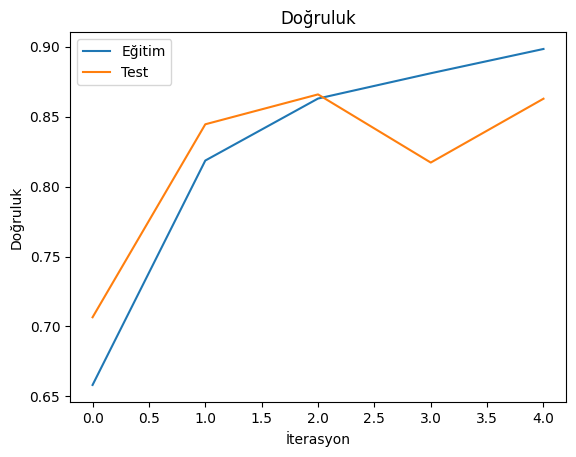

In [41]:
# doğruluğu görselleştirelim
plt.figure()
plt.plot(tarih.history["accuracy"], label="Eğitim")
plt.plot(tarih.history["val_accuracy"], label="Test")
plt.title("Doğruluk")
plt.ylabel("Doğruluk")
plt.xlabel("İterasyon")
plt.legend()
plt.show()

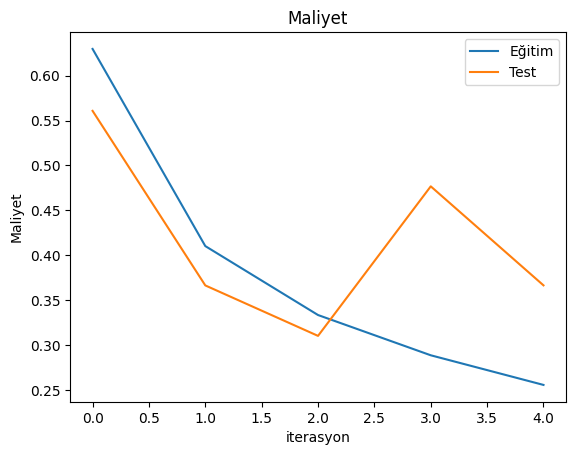

In [45]:
# maliyeti görselleştirelim
plt.figure()
plt.plot(tarih.history["loss"], label="Eğitim")
plt.plot(tarih.history["val_loss"], label="Test")
plt.title("Maliyet")
plt.ylabel("Maliyet")
plt.xlabel("iterasyon")
plt.legend()
plt.show()

In [ ]:
# modelimize manuel yorum verip test ediyoruz
ornek_yorum = "This was an absolute waste of time, boring and terrible from start to finish!"
kelimeler = ornek_yorum.lower().split()
sayisal_dizi = []

for kelime in kelimeler:
    # eğer yazdığımız kelime IMDB'nin 15000 kelimelikk sözlüğünde varsa IDsini al, yoksa yok say
    if kelime in word_index and word_index[kelime] < num_words:
        sayisal_dizi.append(word_index[kelime] + 3)
    else:
        sayisal_dizi.append(2) # sözlükte bulamadığı kelimeler için genel bir bilinmeyen (OOV) kodu koyarız

# eğitim verisinde yaptığımız gibi boyutu 130 kelimeye sabitliyoruz
girdi_matrisi = pad_sequences([sayisal_dizi], maxlen=maxlen)

# modele tahmin yaptırıyoruz
tahmin = rnn.predict(girdi_matrisi)
print(f"Olumlu/Olumsuz Olasılığı: {tahmin[0][0]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step
Olumsuzluk Olasılığı: 0.0037179887294769287
